# AI for Medicine Project

## Comparative Machine Learning for Clinical Disease Prediction Using Breast Cancer and Heart Disease Datasets

This notebook develops and compares supervised machine learning pipelines for two medical binary classification tasks:

1. Breast cancer diagnosis: malignant vs benign.
2. Heart disease prediction: disease vs no disease.

In [261]:
# Data manipulation
import pandas as pd
import numpy as np

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Display settings
pd.set_option('display.max_columns', None)

# Reproducibility
RANDOM_STATE = 42

In [262]:
# Load datasets
breast_df = pd.read_csv("data.csv")
heart_df = pd.read_csv("heart_cleveland_upload.csv")


In [263]:
# First rows of Breast Cancer dataset
breast_df.head()

,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,fractal_dimension_mean,radius_se,texture_se,perimeter_se,area_se,smoothness_se,compactness_se,concavity_se,concave points_se,symmetry_se,fractal_dimension_se,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,1.0950,0.9053,8.589,153.40,0.006399,0.04904,0.05373,0.01587,0.03003,0.006193,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,NaN
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,0.5435,0.7339,3.398,74.08,0.005225,0.01308,0.01860,0.01340,0.01389,0.003532,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,NaN
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,0.7456,0.7869,4.585,94.03,0.006150,0.04006,0.03832,0.02058,0.02250,0.004571,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,NaN
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,0.4956,1.1560,3.445,27.23,0.009110,0.07458,0.05661,0.01867,0.05963,0.009208,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,NaN
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,0.7572,0.7813,5.438,94.44,0.011490,0.02461,0.05688,0.01885,0.01756,0.005115,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,NaN


In [264]:
# First rows of Heart Disease dataset
heart_df.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,condition
0,69,1,0,160,234,1,2,131,0,0.1,1,1,0,0
1,69,0,0,140,239,0,0,151,0,1.8,0,2,0,0
2,66,0,0,150,226,0,0,114,0,2.6,2,0,0,0
3,65,1,0,138,282,1,2,174,0,1.4,1,1,0,1
4,64,1,0,110,211,0,2,144,1,1.8,1,0,0,0


In [265]:
print("Breast Cancer dataset shape:", breast_df.shape)
print("Heart Disease dataset shape:", heart_df.shape)

Breast Cancer dataset shape: (569, 33)
Heart Disease dataset shape: (297, 14)


In [266]:
print("Breast Cancer columns:")
print(breast_df.columns.tolist())

print("\nHeart Disease columns:")
print(heart_df.columns.tolist())

Breast Cancer columns:
['id', 'diagnosis', 'radius_mean', 'texture_mean', 'perimeter_mean', 'area_mean', 'smoothness_mean', 'compactness_mean', 'concavity_mean', 'concave points_mean', 'symmetry_mean', 'fractal_dimension_mean', 'radius_se', 'texture_se', 'perimeter_se', 'area_se', 'smoothness_se', 'compactness_se', 'concavity_se', 'concave points_se', 'symmetry_se', 'fractal_dimension_se', 'radius_worst', 'texture_worst', 'perimeter_worst', 'area_worst', 'smoothness_worst', 'compactness_worst', 'concavity_worst', 'concave points_worst', 'symmetry_worst', 'fractal_dimension_worst', 'Unnamed: 32']

Heart Disease columns:
['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal', 'condition']


In [267]:
print("Breast Cancer data types:")
print(breast_df.dtypes)

print("\nHeart Disease data types:")
print(heart_df.dtypes)

Breast Cancer data types:
id                           int64
diagnosis                   object
radius_mean                float64
texture_mean               float64
perimeter_mean             float64
area_mean                  float64
smoothness_mean            float64
compactness_mean           float64
concavity_mean             float64
concave points_mean        float64
symmetry_mean              float64
fractal_dimension_mean     float64
radius_se                  float64
texture_se                 float64
perimeter_se               float64
area_se                    float64
smoothness_se              float64
compactness_se             float64
concavity_se               float64
concave points_se          float64
symmetry_se                float64
fractal_dimension_se       float64
radius_worst               float64
texture_worst              float64
perimeter_worst            float64
area_worst                 float64
smoothness_worst           float64
compactness_worst          fl

In [268]:
print("Missing values in Breast Cancer dataset:")
print(breast_df.isnull().sum())

print("\nMissing values in Heart Disease dataset:")
print(heart_df.isnull().sum())

Missing values in Breast Cancer dataset:
id                           0
diagnosis                    0
radius_mean                  0
texture_mean                 0
perimeter_mean               0
area_mean                    0
smoothness_mean              0
compactness_mean             0
concavity_mean               0
concave points_mean          0
symmetry_mean                0
fractal_dimension_mean       0
radius_se                    0
texture_se                   0
perimeter_se                 0
area_se                      0
smoothness_se                0
compactness_se               0
concavity_se                 0
concave points_se            0
symmetry_se                  0
fractal_dimension_se         0
radius_worst                 0
texture_worst                0
perimeter_worst              0
area_worst                   0
smoothness_worst             0
compactness_worst            0
concavity_worst              0
concave points_worst         0
symmetry_worst               

In [269]:
print("Breast Cancer class counts:")
print(breast_df["diagnosis"].value_counts())

print("\nBreast Cancer class percentages:")
print(breast_df["diagnosis"].value_counts(normalize=True) * 100)

Breast Cancer class counts:
diagnosis
B    357
M    212
Name: count, dtype: int64

Breast Cancer class percentages:
diagnosis
B    62.741652
M    37.258348
Name: proportion, dtype: float64


In [270]:
print("Heart Disease class counts:")
print(heart_df["condition"].value_counts())

print("\nHeart Disease class percentages:")
print(heart_df["condition"].value_counts(normalize=True) * 100)

Heart Disease class counts:
condition
0    160
1    137
Name: count, dtype: int64

Heart Disease class percentages:
condition
0    53.872054
1    46.127946
Name: proportion, dtype: float64


Text(0.5, 0, 'Diagnosis')

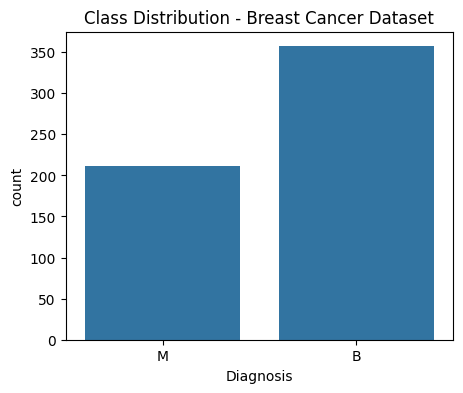

In [271]:
plt.figure(figsize=(5, 4))
sns.countplot(data=breast_df, x="diagnosis")
plt.title("Class Distribution - Breast Cancer Dataset")
plt.xlabel("Diagnosis")


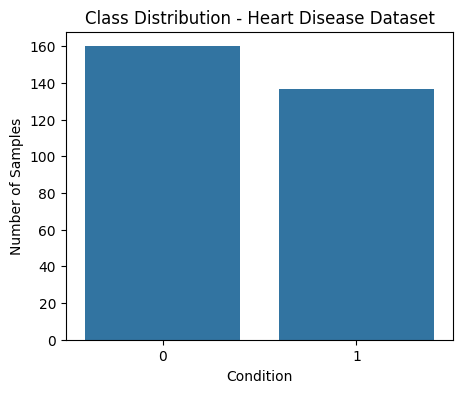

In [272]:
plt.figure(figsize=(5, 4))
sns.countplot(data=heart_df, x="condition")
plt.title("Class Distribution - Heart Disease Dataset")
plt.xlabel("Condition")
plt.ylabel("Number of Samples")
plt.show()

In [273]:
breast_df.describe()

,id,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,fractal_dimension_mean,radius_se,texture_se,perimeter_se,area_se,smoothness_se,compactness_se,concavity_se,concave points_se,symmetry_se,fractal_dimension_se,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
count,5.690000e+02,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,0.0
mean,3.037183e+07,14.127292,19.289649,91.969033,654.889104,0.096360,0.104341,0.088799,0.048919,0.181162,0.062798,0.405172,1.216853,2.866059,40.337079,0.007041,0.025478,0.031894,0.011796,0.020542,0.003795,16.269190,25.677223,107.261213,880.583128,0.132369,0.254265,0.272188,0.114606,0.290076,0.083946,NaN
std,1.250206e+08,3.524049,4.301036,24.298981,351.914129,0.014064,0.052813,0.079720,0.038803,0.027414,0.007060,0.277313,0.551648,2.021855,45.491006,0.003003,0.017908,0.030186,0.006170,0.008266,0.002646,4.833242,6.146258,33.602542,569.356993,0.022832,0.157336,0.208624,0.065732,0.061867,0.018061,NaN
min,8.670000e+03,6.981000,9.710000,43.790000,143.500000,0.052630,0.019380,0.000000,0.000000,0.106000,0.049960,0.111500,0.360200,0.757000,6.802000,0.001713,0.002252,0.000000,0.000000,0.007882,0.000895,7.930000,12.020000,50.410000,185.200000,0.071170,0.027290,0.000000,0.000000,0.156500,0.055040,NaN
25%,8.692180e+05,11.700000,16.170000,75.170000,420.300000,0.086370,0.064920,0.029560,0.020310,0.161900,0.057700,0.232400,0.833900,1.606000,17.850000,0.005169,0.013080,0.015090,0.007638,0.015160,0.002248,13.010000,21.080000,84.110000,515.300000,0.116600,0.147200,0.114500,0.064930,0.250400,0.071460,NaN
50%,9.060240e+05,13.370000,18.840000,86.240000,551.100000,0.095870,0.092630,0.061540,0.033500,0.179200,0.061540,0.324200,1.108000,2.287000,24.530000,0.006380,0.020450,0.025890,0.010930,0.018730,0.003187,14.970000,25.410000,97.660000,686.500000,0.131300,0.211900,0.226700,0.099930,0.282200,0.080040,NaN
75%,8.813129e+06,15.780000,21.800000,104.100000,782.700000,0.105300,0.130400,0.130700,0.074000,0.195700,0.066120,0.478900,1.474000,3.357000,45.190000,0.008146,0.032450,0.042050,0.014710,0.023480,0.004558,18.790000,29.720000,125.400000,1084.000000,0.146000,0.339100,0.382900,0.161400,0.317900,0.092080,NaN
max,9.113205e+08,28.110000,39.280000,188.500000,2501.000000,0.163400,0.345400,0.426800,0.201200,0.304000,0.097440,2.873000,4.885000,21.980000,542.200000,0.031130,0.135400,0.396000,0.052790,0.078950,0.029840,36.040000,49.540000,251.200000,4254.000000,0.222600,1.058000,1.252000,0.291000,0.663800,0.207500,NaN


In [274]:
heart_df.describe()


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,condition
count,297.000000,297.000000,297.000000,297.000000,297.000000,297.000000,297.000000,297.000000,297.000000,297.000000,297.000000,297.000000,297.000000,297.000000
mean,54.542088,0.676768,2.158249,131.693603,247.350168,0.144781,0.996633,149.599327,0.326599,1.055556,0.602694,0.676768,0.835017,0.461279
std,9.049736,0.468500,0.964859,17.762806,51.997583,0.352474,0.994914,22.941562,0.469761,1.166123,0.618187,0.938965,0.956690,0.499340
min,29.000000,0.000000,0.000000,94.000000,126.000000,0.000000,0.000000,71.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,48.000000,0.000000,2.000000,120.000000,211.000000,0.000000,0.000000,133.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,56.000000,1.000000,2.000000,130.000000,243.000000,0.000000,1.000000,153.000000,0.000000,0.800000,1.000000,0.000000,0.000000,0.000000
75%,61.000000,1.000000,3.000000,140.000000,276.000000,0.000000,2.000000,166.000000,1.000000,1.600000,1.000000,1.000000,2.000000,1.000000
max,77.000000,1.000000,3.000000,200.000000,564.000000,1.000000,2.000000,202.000000,1.000000,6.200000,2.000000,3.000000,2.000000,1.000000


In [275]:
# Define features and target for Heart Disease dataset
X_heart = heart_df.drop(columns=["condition"])
y_heart = heart_df["condition"]

print("Heart Disease features shape:", X_heart.shape)
print("Heart Disease target shape:", y_heart.shape)

Heart Disease features shape: (297, 13)
Heart Disease target shape: (297,)


In [276]:
# Remove possible unnamed/empty columns from Breast Cancer dataset
breast_df = breast_df.loc[:, ~breast_df.columns.str.contains("^Unnamed")]

# Define features and target again for Breast Cancer dataset
X_breast = breast_df.drop(columns=["id", "diagnosis"])
y_breast = breast_df["diagnosis"]

print("Breast Cancer features shape:", X_breast.shape)
print("Breast Cancer target shape:", y_breast.shape)
print("Number of Breast Cancer features:", X_breast.shape[1])

Breast Cancer features shape: (569, 30)
Breast Cancer target shape: (569,)
Number of Breast Cancer features: 30


In [277]:
print("Breast Cancer feature columns:")
print(X_breast.columns.tolist())

print("\nHeart Disease feature columns:")
print(X_heart.columns.tolist())


Breast Cancer feature columns:
['radius_mean', 'texture_mean', 'perimeter_mean', 'area_mean', 'smoothness_mean', 'compactness_mean', 'concavity_mean', 'concave points_mean', 'symmetry_mean', 'fractal_dimension_mean', 'radius_se', 'texture_se', 'perimeter_se', 'area_se', 'smoothness_se', 'compactness_se', 'concavity_se', 'concave points_se', 'symmetry_se', 'fractal_dimension_se', 'radius_worst', 'texture_worst', 'perimeter_worst', 'area_worst', 'smoothness_worst', 'compactness_worst', 'concavity_worst', 'concave points_worst', 'symmetry_worst', 'fractal_dimension_worst']

Heart Disease feature columns:
['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal']


In [278]:
# Check Breast Cancer columns
print(breast_df.columns.tolist())

['id', 'diagnosis', 'radius_mean', 'texture_mean', 'perimeter_mean', 'area_mean', 'smoothness_mean', 'compactness_mean', 'concavity_mean', 'concave points_mean', 'symmetry_mean', 'fractal_dimension_mean', 'radius_se', 'texture_se', 'perimeter_se', 'area_se', 'smoothness_se', 'compactness_se', 'concavity_se', 'concave points_se', 'symmetry_se', 'fractal_dimension_se', 'radius_worst', 'texture_worst', 'perimeter_worst', 'area_worst', 'smoothness_worst', 'compactness_worst', 'concavity_worst', 'concave points_worst', 'symmetry_worst', 'fractal_dimension_worst']


In [279]:
# Encode Breast Cancer target
y_breast_encoded = y_breast.map({"B": 0, "M": 1})

# Heart Disease target is already encoded as 0/1
y_heart_encoded = y_heart.copy()

print("Breast Cancer encoded target distribution:")
print(y_breast_encoded.value_counts())

print("\nHeart Disease target distribution:")
print(y_heart_encoded.value_counts())

Breast Cancer encoded target distribution:
diagnosis
0    357
1    212
Name: count, dtype: int64

Heart Disease target distribution:
condition
0    160
1    137
Name: count, dtype: int64


In [280]:
from sklearn.model_selection import train_test_split

In [281]:
# Train/test split for Breast Cancer dataset
X_breast_train, X_breast_test, y_breast_train, y_breast_test = train_test_split(
    X_breast,
    y_breast_encoded,
    test_size=0.2,
    stratify=y_breast_encoded,
    random_state=RANDOM_STATE
)

# Train/test split for Heart Disease dataset
X_heart_train, X_heart_test, y_heart_train, y_heart_test = train_test_split(
    X_heart,
    y_heart_encoded,
    test_size=0.2,
    stratify=y_heart_encoded,
    random_state=RANDOM_STATE
)

print("Breast Cancer train shape:", X_breast_train.shape)
print("Breast Cancer test shape:", X_breast_test.shape)

print("\nHeart Disease train shape:", X_heart_train.shape)
print("Heart Disease test shape:", X_heart_test.shape)

Breast Cancer train shape: (455, 30)
Breast Cancer test shape: (114, 30)

Heart Disease train shape: (237, 13)
Heart Disease test shape: (60, 13)


In [282]:
print("Breast Cancer class distribution - full dataset:")
print(y_breast_encoded.value_counts(normalize=True))

print("\nBreast Cancer class distribution - train:")
print(y_breast_train.value_counts(normalize=True))

print("\nBreast Cancer class distribution - test:")
print(y_breast_test.value_counts(normalize=True))

print("\n-----------------------------\n")

print("Heart Disease class distribution - full dataset:")
print(y_heart_encoded.value_counts(normalize=True))

print("\nHeart Disease class distribution - train:")
print(y_heart_train.value_counts(normalize=True))

print("\nHeart Disease class distribution - test:")
print(y_heart_test.value_counts(normalize=True))

Breast Cancer class distribution - full dataset:
diagnosis
0    0.627417
1    0.372583
Name: proportion, dtype: float64

Breast Cancer class distribution - train:
diagnosis
0    0.626374
1    0.373626
Name: proportion, dtype: float64

Breast Cancer class distribution - test:
diagnosis
0    0.631579
1    0.368421
Name: proportion, dtype: float64

-----------------------------

Heart Disease class distribution - full dataset:
condition
0    0.538721
1    0.461279
Name: proportion, dtype: float64

Heart Disease class distribution - train:
condition
0    0.540084
1    0.459916
Name: proportion, dtype: float64

Heart Disease class distribution - test:
condition
0    0.533333
1    0.466667
Name: proportion, dtype: float64


In [283]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

In [284]:
# StandardScaler will be used later inside machine learning pipelines
scaler = StandardScaler()

print("StandardScaler is ready, but it has not been fitted yet.")

StandardScaler is ready, but it has not been fitted yet.


In [285]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

In [286]:
# Logistic Regression pipeline for Breast Cancer dataset
breast_logreg_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))
])

In [287]:
# Train Logistic Regression model on Breast Cancer training data
breast_logreg_pipeline.fit(X_breast_train, y_breast_train)

Pipeline(steps=[('scaler', StandardScaler()),
                ('classifier',
                 LogisticRegression(max_iter=1000, random_state=42))])

In [288]:
# Predict Breast Cancer test labels
y_breast_pred_logreg = breast_logreg_pipeline.predict(X_breast_test)

In [289]:
print("Breast Cancer - Logistic Regression Results")
print("------------------------------------------")

breast_accuracy = accuracy_score(y_breast_test, y_breast_pred_logreg)
print("Accuracy:", breast_accuracy)

print("\nConfusion Matrix:")
print(confusion_matrix(y_breast_test, y_breast_pred_logreg))

print("\nClassification Report:")
print(classification_report(y_breast_test, y_breast_pred_logreg))

Breast Cancer - Logistic Regression Results
------------------------------------------
Accuracy: 0.9649122807017544

Confusion Matrix:
[[71  1]
 [ 3 39]]

Classification Report:
              precision    recall  f1-score   support

           0       0.96      0.99      0.97        72
           1       0.97      0.93      0.95        42

    accuracy                           0.96       114
   macro avg       0.97      0.96      0.96       114
weighted avg       0.97      0.96      0.96       114



In [290]:
# Logistic Regression pipeline for Heart Disease dataset
heart_logreg_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))
])

In [291]:
# Train Logistic Regression model on Heart Disease training data
heart_logreg_pipeline.fit(X_heart_train, y_heart_train)

Pipeline(steps=[('scaler', StandardScaler()),
                ('classifier',
                 LogisticRegression(max_iter=1000, random_state=42))])

In [292]:
# Predict Heart Disease test labels
y_heart_pred_logreg = heart_logreg_pipeline.predict(X_heart_test)

In [293]:
print("Heart Disease - Logistic Regression Results")
print("------------------------------------------")

heart_accuracy = accuracy_score(y_heart_test, y_heart_pred_logreg)
print("Accuracy:", heart_accuracy)

print("\nConfusion Matrix:")
print(confusion_matrix(y_heart_test, y_heart_pred_logreg))

print("\nClassification Report:")
print(classification_report(y_heart_test, y_heart_pred_logreg))

Heart Disease - Logistic Regression Results
------------------------------------------
Accuracy: 0.9166666666666666

Confusion Matrix:
[[32  0]
 [ 5 23]]

Classification Report:
              precision    recall  f1-score   support

           0       0.86      1.00      0.93        32
           1       1.00      0.82      0.90        28

    accuracy                           0.92        60
   macro avg       0.93      0.91      0.91        60
weighted avg       0.93      0.92      0.92        60



In [294]:
baseline_results = pd.DataFrame({
    "Dataset": ["Breast Cancer", "Heart Disease"],
    "Model": ["Logistic Regression", "Logistic Regression"],
    "Accuracy": [breast_accuracy, heart_accuracy]
})

baseline_results

,Dataset,Model,Accuracy
0,Breast Cancer,Logistic Regression,0.964912
1,Heart Disease,Logistic Regression,0.916667


In [295]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC

In [296]:
# Random Forest pipeline for Breast Cancer dataset
breast_rf_pipeline = Pipeline([
    ("classifier", RandomForestClassifier(
        n_estimators=100,
        random_state=RANDOM_STATE
    ))
])

In [297]:
# Train Random Forest on Breast Cancer training data
breast_rf_pipeline.fit(X_breast_train, y_breast_train)


Pipeline(steps=[('classifier', RandomForestClassifier(random_state=42))])

In [298]:
# Predict Breast Cancer test labels using Random Forest
y_breast_pred_rf = breast_rf_pipeline.predict(X_breast_test)

In [299]:
print("Breast Cancer - Random Forest Results")
print("------------------------------------")

breast_rf_accuracy = accuracy_score(y_breast_test, y_breast_pred_rf)
print("Accuracy:", breast_rf_accuracy)

print("\nConfusion Matrix:")
print(confusion_matrix(y_breast_test, y_breast_pred_rf))

print("\nClassification Report:")
print(classification_report(y_breast_test, y_breast_pred_rf))

Breast Cancer - Random Forest Results
------------------------------------
Accuracy: 0.9736842105263158

Confusion Matrix:
[[72  0]
 [ 3 39]]

Classification Report:
              precision    recall  f1-score   support

           0       0.96      1.00      0.98        72
           1       1.00      0.93      0.96        42

    accuracy                           0.97       114
   macro avg       0.98      0.96      0.97       114
weighted avg       0.97      0.97      0.97       114



In [300]:
# Random Forest pipeline for Heart Disease dataset
heart_rf_pipeline = Pipeline([
    ("classifier", RandomForestClassifier(
        n_estimators=100,
        random_state=RANDOM_STATE
    ))
])

In [301]:
# Train Random Forest on Heart Disease training data
heart_rf_pipeline.fit(X_heart_train, y_heart_train)

Pipeline(steps=[('classifier', RandomForestClassifier(random_state=42))])

In [302]:
# Predict Heart Disease test labels using Random Forest
y_heart_pred_rf = heart_rf_pipeline.predict(X_heart_test)

In [303]:
print("Heart Disease - Random Forest Results")
print("------------------------------------")

heart_rf_accuracy = accuracy_score(y_heart_test, y_heart_pred_rf)
print("Accuracy:", heart_rf_accuracy)

print("\nConfusion Matrix:")
print(confusion_matrix(y_heart_test, y_heart_pred_rf))

print("\nClassification Report:")
print(classification_report(y_heart_test, y_heart_pred_rf))

Heart Disease - Random Forest Results
------------------------------------
Accuracy: 0.8833333333333333

Confusion Matrix:
[[31  1]
 [ 6 22]]

Classification Report:
              precision    recall  f1-score   support

           0       0.84      0.97      0.90        32
           1       0.96      0.79      0.86        28

    accuracy                           0.88        60
   macro avg       0.90      0.88      0.88        60
weighted avg       0.89      0.88      0.88        60



In [304]:
# SVM pipeline for Breast Cancer dataset
breast_svm_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", SVC(
        kernel="rbf",
        probability=True,
        random_state=RANDOM_STATE
    ))
])

In [305]:
# Train SVM on Breast Cancer training data
breast_svm_pipeline.fit(X_breast_train, y_breast_train)

Pipeline(steps=[('scaler', StandardScaler()),
                ('classifier', SVC(probability=True, random_state=42))])

In [306]:
# Predict Breast Cancer test labels using SVM
y_breast_pred_svm = breast_svm_pipeline.predict(X_breast_test)

In [307]:
print("Breast Cancer - SVM Results")
print("---------------------------")

breast_svm_accuracy = accuracy_score(y_breast_test, y_breast_pred_svm)
print("Accuracy:", breast_svm_accuracy)

print("\nConfusion Matrix:")
print(confusion_matrix(y_breast_test, y_breast_pred_svm))

print("\nClassification Report:")
print(classification_report(y_breast_test, y_breast_pred_svm))

Breast Cancer - SVM Results
---------------------------
Accuracy: 0.9736842105263158

Confusion Matrix:
[[72  0]
 [ 3 39]]

Classification Report:
              precision    recall  f1-score   support

           0       0.96      1.00      0.98        72
           1       1.00      0.93      0.96        42

    accuracy                           0.97       114
   macro avg       0.98      0.96      0.97       114
weighted avg       0.97      0.97      0.97       114



In [308]:
# SVM pipeline for Heart Disease dataset
heart_svm_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", SVC(
        kernel="rbf",
        probability=True,
        random_state=RANDOM_STATE
    ))
])

In [309]:
# Train SVM on Heart Disease training data
heart_svm_pipeline.fit(X_heart_train, y_heart_train)


Pipeline(steps=[('scaler', StandardScaler()),
                ('classifier', SVC(probability=True, random_state=42))])

In [310]:
# Predict Heart Disease test labels using SVM
y_heart_pred_svm = heart_svm_pipeline.predict(X_heart_test)

In [311]:
print("Heart Disease - SVM Results")
print("---------------------------")

heart_svm_accuracy = accuracy_score(y_heart_test, y_heart_pred_svm)
print("Accuracy:", heart_svm_accuracy)

print("\nConfusion Matrix:")
print(confusion_matrix(y_heart_test, y_heart_pred_svm))

print("\nClassification Report:")
print(classification_report(y_heart_test, y_heart_pred_svm))

Heart Disease - SVM Results
---------------------------
Accuracy: 0.9

Confusion Matrix:
[[32  0]
 [ 6 22]]

Classification Report:
              precision    recall  f1-score   support

           0       0.84      1.00      0.91        32
           1       1.00      0.79      0.88        28

    accuracy                           0.90        60
   macro avg       0.92      0.89      0.90        60
weighted avg       0.92      0.90      0.90        60



In [312]:
accuracy_results = pd.DataFrame({
    "Dataset": [
        "Breast Cancer", "Breast Cancer", "Breast Cancer",
        "Heart Disease", "Heart Disease", "Heart Disease"
    ],
    "Model": [
        "Logistic Regression", "Random Forest", "SVM",
        "Logistic Regression", "Random Forest", "SVM"
    ],
    "Accuracy": [
        breast_accuracy, breast_rf_accuracy, breast_svm_accuracy,
        heart_accuracy, heart_rf_accuracy, heart_svm_accuracy
    ]
})

accuracy_results

,Dataset,Model,Accuracy
0,Breast Cancer,Logistic Regression,0.964912
1,Breast Cancer,Random Forest,0.973684
2,Breast Cancer,SVM,0.973684
3,Heart Disease,Logistic Regression,0.916667
4,Heart Disease,Random Forest,0.883333
5,Heart Disease,SVM,0.900000


In [313]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    roc_auc_score,
    roc_curve
)

In [314]:
def evaluate_classification_model(model, X_test, y_test, y_pred, dataset_name, model_name):
    """
    Evaluate a binary classification model using clinically relevant metrics.
    Positive class is assumed to be 1.
    """

    # Confusion matrix with fixed label order: 0 = negative, 1 = positive
    tn, fp, fn, tp = confusion_matrix(y_test, y_pred, labels=[0, 1]).ravel()

    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred, pos_label=1)
    sensitivity = recall_score(y_test, y_pred, pos_label=1)  # same as recall / TPR
    specificity = tn / (tn + fp)
    f1 = f1_score(y_test, y_pred, pos_label=1)

    # Predicted probabilities for ROC-AUC
    y_score = model.predict_proba(X_test)[:, 1]
    auc = roc_auc_score(y_test, y_score)

    results = {
        "Dataset": dataset_name,
        "Model": model_name,
        "Accuracy": accuracy,
        "Sensitivity": sensitivity,
        "Specificity": specificity,
        "Precision": precision,
        "F1-score": f1,
        "ROC-AUC": auc,
        "TN": tn,
        "FP": fp,
        "FN": fn,
        "TP": tp
    }

    return results

In [315]:
breast_results = []

breast_results.append(
    evaluate_classification_model(
        breast_logreg_pipeline,
        X_breast_test,
        y_breast_test,
        y_breast_pred_logreg,
        "Breast Cancer",
        "Logistic Regression"
    )
)

breast_results.append(
    evaluate_classification_model(
        breast_rf_pipeline,
        X_breast_test,
        y_breast_test,
        y_breast_pred_rf,
        "Breast Cancer",
        "Random Forest"
    )
)

breast_results.append(
    evaluate_classification_model(
        breast_svm_pipeline,
        X_breast_test,
        y_breast_test,
        y_breast_pred_svm,
        "Breast Cancer",
        "SVM"
    )
)

breast_results_df = pd.DataFrame(breast_results)
breast_results_df

,Dataset,Model,Accuracy,Sensitivity,Specificity,Precision,F1-score,ROC-AUC,TN,FP,FN,TP
0,Breast Cancer,Logistic Regression,0.964912,0.928571,0.986111,0.975,0.951220,0.996032,71,1,3,39
1,Breast Cancer,Random Forest,0.973684,0.928571,1.000000,1.000,0.962963,0.992890,72,0,3,39
2,Breast Cancer,SVM,0.973684,0.928571,1.000000,1.000,0.962963,0.994709,72,0,3,39


In [316]:
heart_results = []

heart_results.append(
    evaluate_classification_model(
        heart_logreg_pipeline,
        X_heart_test,
        y_heart_test,
        y_heart_pred_logreg,
        "Heart Disease",
        "Logistic Regression"
    )
)

heart_results.append(
    evaluate_classification_model(
        heart_rf_pipeline,
        X_heart_test,
        y_heart_test,
        y_heart_pred_rf,
        "Heart Disease",
        "Random Forest"
    )
)

heart_results.append(
    evaluate_classification_model(
        heart_svm_pipeline,
        X_heart_test,
        y_heart_test,
        y_heart_pred_svm,
        "Heart Disease",
        "SVM"
    )
)

heart_results_df = pd.DataFrame(heart_results)
heart_results_df

,Dataset,Model,Accuracy,Sensitivity,Specificity,Precision,F1-score,ROC-AUC,TN,FP,FN,TP
0,Heart Disease,Logistic Regression,0.916667,0.821429,1.00000,1.000000,0.901961,0.953125,32,0,5,23
1,Heart Disease,Random Forest,0.883333,0.785714,0.96875,0.956522,0.862745,0.940290,31,1,6,22
2,Heart Disease,SVM,0.900000,0.785714,1.00000,1.000000,0.880000,0.939732,32,0,6,22


In [317]:
all_results_df = pd.concat([breast_results_df, heart_results_df], ignore_index=True)

# Round numeric columns for readability
all_results_df_rounded = all_results_df.copy()
numeric_columns = ["Accuracy", "Sensitivity", "Specificity", "Precision", "F1-score", "ROC-AUC"]
all_results_df_rounded[numeric_columns] = all_results_df_rounded[numeric_columns].round(3)

all_results_df_rounded

,Dataset,Model,Accuracy,Sensitivity,Specificity,Precision,F1-score,ROC-AUC,TN,FP,FN,TP
0,Breast Cancer,Logistic Regression,0.965,0.929,0.986,0.975,0.951,0.996,71,1,3,39
1,Breast Cancer,Random Forest,0.974,0.929,1.000,1.000,0.963,0.993,72,0,3,39
2,Breast Cancer,SVM,0.974,0.929,1.000,1.000,0.963,0.995,72,0,3,39
3,Heart Disease,Logistic Regression,0.917,0.821,1.000,1.000,0.902,0.953,32,0,5,23
4,Heart Disease,Random Forest,0.883,0.786,0.969,0.957,0.863,0.940,31,1,6,22
5,Heart Disease,SVM,0.900,0.786,1.000,1.000,0.880,0.940,32,0,6,22


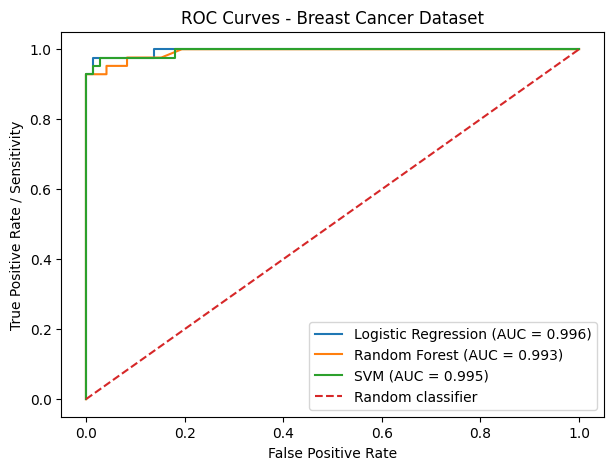

In [318]:
plt.figure(figsize=(7, 5))

breast_models = {
    "Logistic Regression": breast_logreg_pipeline,
    "Random Forest": breast_rf_pipeline,
    "SVM": breast_svm_pipeline
}

for model_name, model in breast_models.items():
    y_score = model.predict_proba(X_breast_test)[:, 1]
    fpr, tpr, thresholds = roc_curve(y_breast_test, y_score)
    auc = roc_auc_score(y_breast_test, y_score)
    plt.plot(fpr, tpr, label=f"{model_name} (AUC = {auc:.3f})")

plt.plot([0, 1], [0, 1], linestyle="--", label="Random classifier")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate / Sensitivity")
plt.title("ROC Curves - Breast Cancer Dataset")
plt.legend()
plt.show()

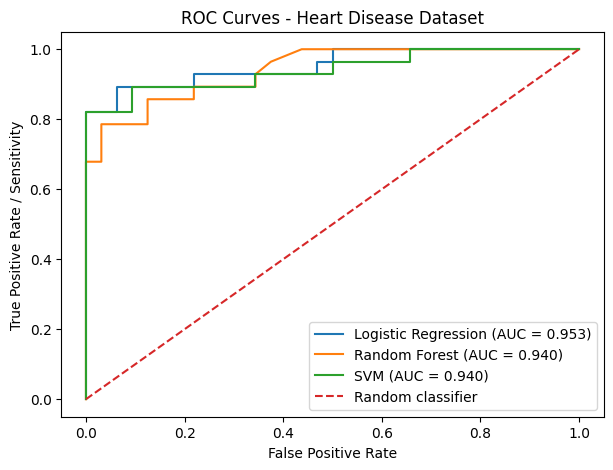

In [319]:
plt.figure(figsize=(7, 5))

heart_models = {
    "Logistic Regression": heart_logreg_pipeline,
    "Random Forest": heart_rf_pipeline,
    "SVM": heart_svm_pipeline
}

for model_name, model in heart_models.items():
    y_score = model.predict_proba(X_heart_test)[:, 1]
    fpr, tpr, thresholds = roc_curve(y_heart_test, y_score)
    auc = roc_auc_score(y_heart_test, y_score)
    plt.plot(fpr, tpr, label=f"{model_name} (AUC = {auc:.3f})")

plt.plot([0, 1], [0, 1], linestyle="--", label="Random classifier")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate / Sensitivity")
plt.title("ROC Curves - Heart Disease Dataset")
plt.legend()
plt.show()

In [320]:
best_breast_model_name = breast_results_df.loc[breast_results_df["ROC-AUC"].idxmax(), "Model"]
best_heart_model_name = heart_results_df.loc[heart_results_df["ROC-AUC"].idxmax(), "Model"]

print("Best Breast Cancer model based on ROC-AUC:", best_breast_model_name)
print("Best Heart Disease model based on ROC-AUC:", best_heart_model_name)

Best Breast Cancer model based on ROC-AUC: Logistic Regression
Best Heart Disease model based on ROC-AUC: Logistic Regression


In [321]:
def plot_confusion_matrix(y_true, y_pred, title):
    cm = confusion_matrix(y_true, y_pred, labels=[0, 1])

    plt.figure(figsize=(5, 4))
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["Predicted 0", "Predicted 1"],
        yticklabels=["Actual 0", "Actual 1"]
    )
    plt.title(title)
    plt.xlabel("Predicted label")
    plt.ylabel("True label")
    plt.show()

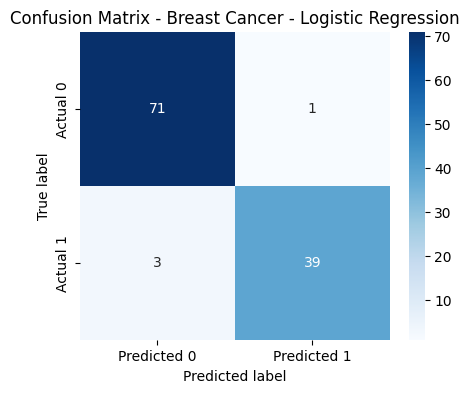

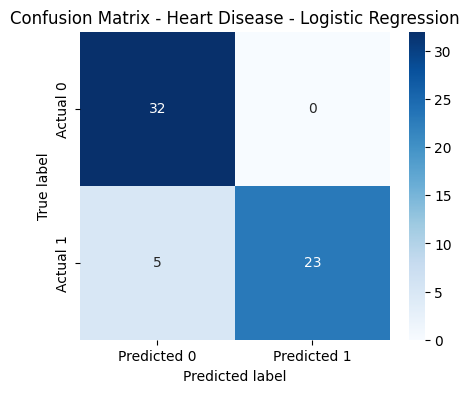

In [322]:
plot_confusion_matrix(
    y_breast_test,
    y_breast_pred_logreg,
    "Confusion Matrix - Breast Cancer - Logistic Regression"
)

plot_confusion_matrix(
    y_heart_test,
    y_heart_pred_logreg,
    "Confusion Matrix - Heart Disease - Logistic Regression"
)


In [323]:
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.metrics import make_scorer


In [324]:
def specificity_score(y_true, y_pred):
    """
    Specificity = TN / (TN + FP)
    Measures how well the model identifies negative cases.
    """
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    return tn / (tn + fp)

specificity_scorer = make_scorer(specificity_score)

In [325]:
cv_strategy = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

In [326]:
scoring_metrics = {
    "accuracy": "accuracy",
    "precision": "precision",
    "sensitivity": "recall",
    "specificity": specificity_scorer,
    "f1": "f1",
    "roc_auc": "roc_auc"
}

In [327]:
breast_cv_models = {
    "Logistic Regression": breast_logreg_pipeline,
    "Random Forest": breast_rf_pipeline,
    "SVM": breast_svm_pipeline
}

In [328]:
heart_cv_models = {
    "Logistic Regression": heart_logreg_pipeline,
    "Random Forest": heart_rf_pipeline,
    "SVM": heart_svm_pipeline
}

In [329]:
def run_cross_validation(models, X_train, y_train, dataset_name):
    """
    Run stratified 5-fold cross-validation on the training set only.
    Test set is not used here.
    """
    cv_results = []

    for model_name, model in models.items():
        scores = cross_validate(
            model,
            X_train,
            y_train,
            cv=cv_strategy,
            scoring=scoring_metrics,
            return_train_score=False
        )

        result = {
            "Dataset": dataset_name,
            "Model": model_name,
            "CV Accuracy Mean": scores["test_accuracy"].mean(),
            "CV Accuracy Std": scores["test_accuracy"].std(),
            "CV Sensitivity Mean": scores["test_sensitivity"].mean(),
            "CV Specificity Mean": scores["test_specificity"].mean(),
            "CV Precision Mean": scores["test_precision"].mean(),
            "CV F1 Mean": scores["test_f1"].mean(),
            "CV ROC-AUC Mean": scores["test_roc_auc"].mean(),
            "CV ROC-AUC Std": scores["test_roc_auc"].std()
        }

        cv_results.append(result)

    return pd.DataFrame(cv_results)

In [330]:
breast_cv_results_df = run_cross_validation(
    breast_cv_models,
    X_breast_train,
    y_breast_train,
    "Breast Cancer"
)

breast_cv_results_df.round(3)

,Dataset,Model,CV Accuracy Mean,CV Accuracy Std,CV Sensitivity Mean,CV Specificity Mean,CV Precision Mean,CV F1 Mean,CV ROC-AUC Mean,CV ROC-AUC Std
0,Breast Cancer,Logistic Regression,0.974,0.015,0.953,0.986,0.977,0.964,0.996,0.005
1,Breast Cancer,Random Forest,0.965,0.015,0.941,0.979,0.964,0.952,0.989,0.007
2,Breast Cancer,SVM,0.971,0.005,0.947,0.986,0.977,0.961,0.995,0.005


In [331]:
heart_cv_results_df = run_cross_validation(
    heart_cv_models,
    X_heart_train,
    y_heart_train,
    "Heart Disease"
)

heart_cv_results_df.round(3)

,Dataset,Model,CV Accuracy Mean,CV Accuracy Std,CV Sensitivity Mean,CV Specificity Mean,CV Precision Mean,CV F1 Mean,CV ROC-AUC Mean,CV ROC-AUC Std
0,Heart Disease,Logistic Regression,0.823,0.053,0.782,0.860,0.825,0.800,0.876,0.045
1,Heart Disease,Random Forest,0.764,0.040,0.717,0.806,0.764,0.732,0.872,0.033
2,Heart Disease,SVM,0.790,0.068,0.763,0.814,0.788,0.769,0.872,0.044


In [332]:
all_cv_results_df = pd.concat(
    [breast_cv_results_df, heart_cv_results_df],
    ignore_index=True
)

all_cv_results_df_rounded = all_cv_results_df.round(3)
all_cv_results_df_rounded

,Dataset,Model,CV Accuracy Mean,CV Accuracy Std,CV Sensitivity Mean,CV Specificity Mean,CV Precision Mean,CV F1 Mean,CV ROC-AUC Mean,CV ROC-AUC Std
0,Breast Cancer,Logistic Regression,0.974,0.015,0.953,0.986,0.977,0.964,0.996,0.005
1,Breast Cancer,Random Forest,0.965,0.015,0.941,0.979,0.964,0.952,0.989,0.007
2,Breast Cancer,SVM,0.971,0.005,0.947,0.986,0.977,0.961,0.995,0.005
3,Heart Disease,Logistic Regression,0.823,0.053,0.782,0.860,0.825,0.800,0.876,0.045
4,Heart Disease,Random Forest,0.764,0.040,0.717,0.806,0.764,0.732,0.872,0.033
5,Heart Disease,SVM,0.790,0.068,0.763,0.814,0.788,0.769,0.872,0.044


In [333]:
all_cv_results_df_rounded


,Dataset,Model,CV Accuracy Mean,CV Accuracy Std,CV Sensitivity Mean,CV Specificity Mean,CV Precision Mean,CV F1 Mean,CV ROC-AUC Mean,CV ROC-AUC Std
0,Breast Cancer,Logistic Regression,0.974,0.015,0.953,0.986,0.977,0.964,0.996,0.005
1,Breast Cancer,Random Forest,0.965,0.015,0.941,0.979,0.964,0.952,0.989,0.007
2,Breast Cancer,SVM,0.971,0.005,0.947,0.986,0.977,0.961,0.995,0.005
3,Heart Disease,Logistic Regression,0.823,0.053,0.782,0.860,0.825,0.800,0.876,0.045
4,Heart Disease,Random Forest,0.764,0.040,0.717,0.806,0.764,0.732,0.872,0.033
5,Heart Disease,SVM,0.790,0.068,0.763,0.814,0.788,0.769,0.872,0.044


In [334]:
all_results_df_rounded

,Dataset,Model,Accuracy,Sensitivity,Specificity,Precision,F1-score,ROC-AUC,TN,FP,FN,TP
0,Breast Cancer,Logistic Regression,0.965,0.929,0.986,0.975,0.951,0.996,71,1,3,39
1,Breast Cancer,Random Forest,0.974,0.929,1.000,1.000,0.963,0.993,72,0,3,39
2,Breast Cancer,SVM,0.974,0.929,1.000,1.000,0.963,0.995,72,0,3,39
3,Heart Disease,Logistic Regression,0.917,0.821,1.000,1.000,0.902,0.953,32,0,5,23
4,Heart Disease,Random Forest,0.883,0.786,0.969,0.957,0.863,0.940,31,1,6,22
5,Heart Disease,SVM,0.900,0.786,1.000,1.000,0.880,0.940,32,0,6,22


## Data Leakage Prevention

To reduce the risk of data leakage, the following precautions were applied:

- The test set was separated before final model evaluation.
- Cross-validation was performed only on the training set.
- Feature scaling was included inside scikit-learn pipelines.
- The scaler was fitted only on training folds during cross-validation.
- The independent test set was not used for model selection or preprocessing.
- Target variables were removed from the feature matrices.
- Identifier columns such as `id` were removed from the Breast Cancer dataset.

In [335]:
from sklearn.model_selection import GridSearchCV

In [336]:
# Hyperparameter grids for light tuning

logreg_param_grid = {
    "classifier__C": [0.01, 0.1, 1, 10]
}

rf_param_grid = {
    "classifier__n_estimators": [100, 200],
    "classifier__max_depth": [None, 5, 10]
}

svm_param_grid = {
    "classifier__C": [0.1, 1, 10],
    "classifier__gamma": ["scale", "auto"]
}

In [337]:
def tune_model_with_grid_search(pipeline, param_grid, X_train, y_train, dataset_name, model_name):
    """
    Tune hyperparameters using GridSearchCV on the training set only.
    The test set is not used during tuning.
    """

    grid_search = GridSearchCV(
        estimator=pipeline,
        param_grid=param_grid,
        scoring="roc_auc",
        cv=cv_strategy,
        n_jobs=-1
    )

    grid_search.fit(X_train, y_train)

    print(f"{dataset_name} - {model_name}")
    print("Best parameters:", grid_search.best_params_)
    print("Best CV ROC-AUC:", grid_search.best_score_)
    print("-----------------------------------")

    return grid_search

In [338]:
breast_logreg_tuned = tune_model_with_grid_search(
    breast_logreg_pipeline,
    logreg_param_grid,
    X_breast_train,
    y_breast_train,
    "Breast Cancer",
    "Logistic Regression"
)

breast_rf_tuned = tune_model_with_grid_search(
    breast_rf_pipeline,
    rf_param_grid,
    X_breast_train,
    y_breast_train,
    "Breast Cancer",
    "Random Forest"
)

breast_svm_tuned = tune_model_with_grid_search(
    breast_svm_pipeline,
    svm_param_grid,
    X_breast_train,
    y_breast_train,
    "Breast Cancer",
    "SVM"
)

Breast Cancer - Logistic Regression
Best parameters: {'classifier__C': 1}
Best CV ROC-AUC: 0.9957688338493291
-----------------------------------
Breast Cancer - Random Forest
Best parameters: {'classifier__max_depth': 10, 'classifier__n_estimators': 100}
Best CV ROC-AUC: 0.9889576883384933
-----------------------------------
Breast Cancer - SVM
Best parameters: {'classifier__C': 1, 'classifier__gamma': 'scale'}
Best CV ROC-AUC: 0.9949432404540763
-----------------------------------


In [339]:
heart_logreg_tuned = tune_model_with_grid_search(
    heart_logreg_pipeline,
    logreg_param_grid,
    X_heart_train,
    y_heart_train,
    "Heart Disease",
    "Logistic Regression"
)

heart_rf_tuned = tune_model_with_grid_search(
    heart_rf_pipeline,
    rf_param_grid,
    X_heart_train,
    y_heart_train,
    "Heart Disease",
    "Random Forest"
)

heart_svm_tuned = tune_model_with_grid_search(
    heart_svm_pipeline,
    svm_param_grid,
    X_heart_train,
    y_heart_train,
    "Heart Disease",
    "SVM"
)

Heart Disease - Logistic Regression
Best parameters: {'classifier__C': 0.01}
Best CV ROC-AUC: 0.8946460206460207
-----------------------------------
Heart Disease - Random Forest
Best parameters: {'classifier__max_depth': 5, 'classifier__n_estimators': 100}
Best CV ROC-AUC: 0.885078921078921
-----------------------------------
Heart Disease - SVM
Best parameters: {'classifier__C': 0.1, 'classifier__gamma': 'scale'}
Best CV ROC-AUC: 0.8896983016983018
-----------------------------------


In [340]:
tuning_summary = pd.DataFrame({
    "Dataset": [
        "Breast Cancer", "Breast Cancer", "Breast Cancer",
        "Heart Disease", "Heart Disease", "Heart Disease"
    ],
    "Model": [
        "Logistic Regression", "Random Forest", "SVM",
        "Logistic Regression", "Random Forest", "SVM"
    ],
    "Best Parameters": [
        breast_logreg_tuned.best_params_,
        breast_rf_tuned.best_params_,
        breast_svm_tuned.best_params_,
        heart_logreg_tuned.best_params_,
        heart_rf_tuned.best_params_,
        heart_svm_tuned.best_params_
    ],
    "Best CV ROC-AUC": [
        breast_logreg_tuned.best_score_,
        breast_rf_tuned.best_score_,
        breast_svm_tuned.best_score_,
        heart_logreg_tuned.best_score_,
        heart_rf_tuned.best_score_,
        heart_svm_tuned.best_score_
    ]
})

tuning_summary["Best CV ROC-AUC"] = tuning_summary["Best CV ROC-AUC"].round(3)
tuning_summary

,Dataset,Model,Best Parameters,Best CV ROC-AUC
0,Breast Cancer,Logistic Regression,{'classifier__C': 1},0.996
1,Breast Cancer,Random Forest,"{'classifier__max_depth': 10, 'classifier__n_e...",0.989
2,Breast Cancer,SVM,"{'classifier__C': 1, 'classifier__gamma': 'sca...",0.995
3,Heart Disease,Logistic Regression,{'classifier__C': 0.01},0.895
4,Heart Disease,Random Forest,"{'classifier__max_depth': 5, 'classifier__n_es...",0.885
5,Heart Disease,SVM,"{'classifier__C': 0.1, 'classifier__gamma': 's...",0.890


In [341]:
# Breast Cancer tuned predictions
y_breast_pred_logreg_tuned = breast_logreg_tuned.predict(X_breast_test)
y_breast_pred_rf_tuned = breast_rf_tuned.predict(X_breast_test)
y_breast_pred_svm_tuned = breast_svm_tuned.predict(X_breast_test)

# Heart Disease tuned predictions
y_heart_pred_logreg_tuned = heart_logreg_tuned.predict(X_heart_test)
y_heart_pred_rf_tuned = heart_rf_tuned.predict(X_heart_test)
y_heart_pred_svm_tuned = heart_svm_tuned.predict(X_heart_test)

In [342]:
tuned_results = []

tuned_results.append(
    evaluate_classification_model(
        breast_logreg_tuned,
        X_breast_test,
        y_breast_test,
        y_breast_pred_logreg_tuned,
        "Breast Cancer",
        "Logistic Regression Tuned"
    )
)

tuned_results.append(
    evaluate_classification_model(
        breast_rf_tuned,
        X_breast_test,
        y_breast_test,
        y_breast_pred_rf_tuned,
        "Breast Cancer",
        "Random Forest Tuned"
    )
)

tuned_results.append(
    evaluate_classification_model(
        breast_svm_tuned,
        X_breast_test,
        y_breast_test,
        y_breast_pred_svm_tuned,
        "Breast Cancer",
        "SVM Tuned"
    )
)

tuned_results.append(
    evaluate_classification_model(
        heart_logreg_tuned,
        X_heart_test,
        y_heart_test,
        y_heart_pred_logreg_tuned,
        "Heart Disease",
        "Logistic Regression Tuned"
    )
)

tuned_results.append(
    evaluate_classification_model(
        heart_rf_tuned,
        X_heart_test,
        y_heart_test,
        y_heart_pred_rf_tuned,
        "Heart Disease",
        "Random Forest Tuned"
    )
)

tuned_results.append(
    evaluate_classification_model(
        heart_svm_tuned,
        X_heart_test,
        y_heart_test,
        y_heart_pred_svm_tuned,
        "Heart Disease",
        "SVM Tuned"
    )
)

tuned_results_df = pd.DataFrame(tuned_results)

numeric_columns = ["Accuracy", "Sensitivity", "Specificity", "Precision", "F1-score", "ROC-AUC"]
tuned_results_df[numeric_columns] = tuned_results_df[numeric_columns].round(3)

tuned_results_df

,Dataset,Model,Accuracy,Sensitivity,Specificity,Precision,F1-score,ROC-AUC,TN,FP,FN,TP
0,Breast Cancer,Logistic Regression Tuned,0.965,0.929,0.986,0.975,0.951,0.996,71,1,3,39
1,Breast Cancer,Random Forest Tuned,0.974,0.929,1.000,1.000,0.963,0.993,72,0,3,39
2,Breast Cancer,SVM Tuned,0.974,0.929,1.000,1.000,0.963,0.995,72,0,3,39
3,Heart Disease,Logistic Regression Tuned,0.867,0.714,1.000,1.000,0.833,0.929,32,0,8,20
4,Heart Disease,Random Forest Tuned,0.833,0.714,0.938,0.909,0.800,0.924,30,2,8,20
5,Heart Disease,SVM Tuned,0.867,0.714,1.000,1.000,0.833,0.926,32,0,8,20


In [343]:
def plot_random_forest_feature_importance(rf_model, feature_names, dataset_name, top_n=10):
    """
    Plot top feature importances from a fitted Random Forest pipeline or tuned GridSearchCV object.
    """

    # If model is GridSearchCV, extract best estimator
    if hasattr(rf_model, "best_estimator_"):
        fitted_pipeline = rf_model.best_estimator_
    else:
        fitted_pipeline = rf_model

    rf_classifier = fitted_pipeline.named_steps["classifier"]

    importances = rf_classifier.feature_importances_

    importance_df = pd.DataFrame({
        "Feature": feature_names,
        "Importance": importances
    }).sort_values(by="Importance", ascending=False)

    top_features = importance_df.head(top_n)

    plt.figure(figsize=(8, 5))
    sns.barplot(data=top_features, x="Importance", y="Feature")
    plt.title(f"Top {top_n} Feature Importances - {dataset_name}")
    plt.xlabel("Feature Importance")
    plt.ylabel("Feature")
    plt.show()

    return importance_df

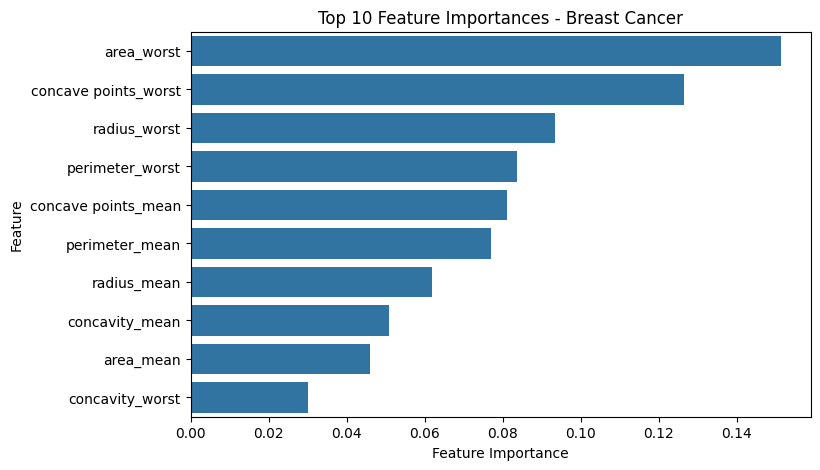

,Feature,Importance
23,area_worst,0.151412
27,concave points_worst,0.126497
20,radius_worst,0.093475
22,perimeter_worst,0.083642
7,concave points_mean,0.081082
2,perimeter_mean,0.077126
0,radius_mean,0.061990
6,concavity_mean,0.050818
3,area_mean,0.045916
26,concavity_worst,0.030022


In [344]:
breast_feature_importance_df = plot_random_forest_feature_importance(
    breast_rf_tuned,
    X_breast.columns,
    "Breast Cancer",
    top_n=10
)

breast_feature_importance_df.head(10)

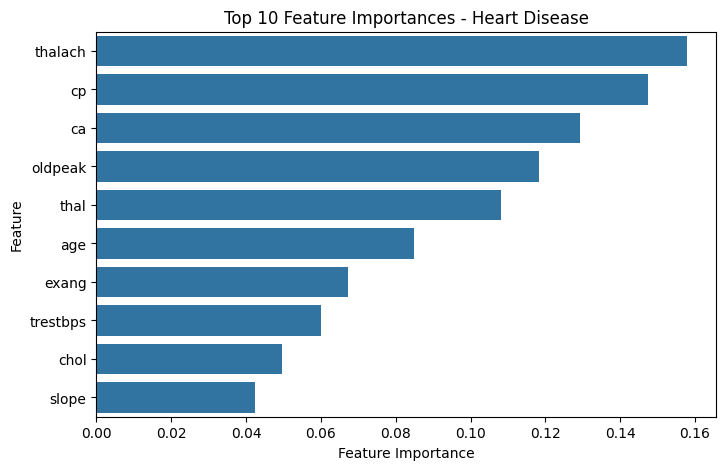

,Feature,Importance
7,thalach,0.157786
2,cp,0.147332
11,ca,0.129174
9,oldpeak,0.118404
12,thal,0.108032
0,age,0.084988
8,exang,0.067182
3,trestbps,0.060098
4,chol,0.049705
10,slope,0.042349


In [345]:
heart_feature_importance_df = plot_random_forest_feature_importance(
    heart_rf_tuned,
    X_heart.columns,
    "Heart Disease",
    top_n=10
)

heart_feature_importance_df.head(10)